# 전체망 A - 곤란구간 확정 v2: 유형 A/B 통합 + 반경 민감도 (최최종)

기존 `최종_곤란구간.ipynb` 대비 바뀐 점 3가지.

1. 유형을 둘로 나눔.
   - 유형 A(주요경로형): 공식 주요경로(is_main)이면서, 큰 우회를 한 O-D들이 최단경로에서 실제로 피해간(n_bypassed) 구간이고, 동시에 heat_norm도 유의하게 뜨거운 구간. 원인이 주요경로 자체의 과열이므로 그 주요경로 위에 그늘막/쉼터를 놓아 애초에 우회할 필요를 없애는 게 목표.
   - 유형 B(회피불가형): 열노출을 줄이려고 우회해도 그 우회로 자체가 여전히 뜨겁고 여러 O-D가 몰리는 구간(기존 노트북의 정의 그대로).
   - 공모전 요강 "최단경로와 대체경로 모두에서 열노출이 높거나, 과도한 우회가 필요한 구간"의 두 조건을 각각 유형 B / 유형 A에 대응시킨 것.

2. 유형 B의 "정확히 같은 링크" 조건(exact)을 지구별 반경 민감도로 완화한 buffered 버전을 병기. exact/buffered 둘 다 순열검정 + 초기하분포 정확검정으로 유의성을 확인.

3. 개수 상한. 통계적으로 유의한 것 중에서도 심각도 상위 일부(지구/유형당 최대 CAP_PER_TYPE_ZONE개)만 확정으로 남김.

입력: 전체망_A_제공데이터만.geojson, od_pairs_주요경로.csv(380쌍), heat_index_grid_final.geojson
출력: A_곤란구간_확정_v2.geojson (좌표계는 기존과 동일하게 EPSG:5179로 저장 - 재변환 안 함)

In [46]:
# 필요 패키지: geopandas, networkx, libpysal, esda, statsmodels, scipy, shapely
import warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, networkx as nx
from shapely.geometry import Point
from shapely.strtree import STRtree
from scipy.spatial import cKDTree
from libpysal.weights import W
from esda.moran import Moran, Moran_Local
from statsmodels.stats.multitest import multipletests
from scipy.stats import hypergeom

warnings.filterwarnings("ignore")
pd.set_option("display.width", 240)

NET_LABEL = "A"
NET_FILE  = "전체망_A_제공데이터만.geojson"
HEAT_GRID_FILE = "heat_index_grid_final.geojson"
OD_FILE   = "od_pairs_주요경로.csv"

BASE_DIR = Path.cwd()
CRS_M          = "EPSG:5179"
ALPHA          = 2.5
SEED           = 42
N_PERMUTATIONS = 9999
N_PERM_SENS    = 999
FDR_Q          = 0.05
MIN_AVOID_USES_CORE = 2
R_GRID = [100, 200, 300, 400, 500, 600, 700, 800, 1000]
CAP_PER_TYPE_ZONE = 15
WARN_PCT = 5.0
BASELINE_CAP = 0.35  # 버퍼 R에서 baseline_rate(전체 링크 중 H 근처 비율)가 이 값을 넘으면
                     # "가깝다"는 조건에 선별력이 없다고 보고 그 R은 후보에서 제외

np.random.seed(SEED)
OUT_PATH = BASE_DIR / f"{NET_LABEL}_곤란구간_확정_v2.geojson"

print(f"[{NET_LABEL}] 설정 완료 - 반경후보 {R_GRID} - 유형당 상한 {CAP_PER_TYPE_ZONE}개/지구 - 출력: {OUT_PATH}")

[A] 설정 완료 - 반경후보 [100, 200, 300, 400, 500, 600, 700, 800, 1000] - 유형당 상한 15개/지구 - 출력: c:\Users\minji\OneDrive\Desktop\폭염데이터\최종\최최종\A_곤란구간_확정_v2.geojson


## STEP 0~2. 데이터 로드, heat_norm 계산, 그래프 구성 (기존과 동일)

In [47]:
E = gpd.read_file(BASE_DIR / NET_FILE).to_crs(CRS_M)
od = pd.read_csv(BASE_DIR / OD_FILE)
print(f"[{NET_LABEL}] {len(E):,}개 링크, O-D {len(od):,}쌍")
print(E.groupby("zone").agg(링크=("length","size"), 연장km=("length", lambda s: round(s.sum()/1000,1))).to_string())

SAMPLE, BUF = 30, 30
def attach_heat(gdf, grid_path):
    hg = gpd.read_file(grid_path).to_crs(CRS_M)
    hg = hg[hg.heat_index.notna()].reset_index(drop=True)
    tree = STRtree(hg.geometry.values)
    vals_all = hg.heat_index.values
    out = []
    for g in gdf.geometry:
        Lg = max(g.length, 1e-6)
        n = min(max(int(Lg // SAMPLE) + 1, 1), 40)
        v = []
        for k in range(n):
            hit = tree.query(g.interpolate(min((k + .5) * Lg / n, Lg)).buffer(BUF), predicate="intersects")
            if len(hit):
                v.append(float(np.mean(vals_all[hit])))
        out.append(np.median(v) if v else np.nan)
    gdf = gdf.copy()
    gdf["heat"] = out
    gdf["heat"] = gdf["heat"].fillna(gdf.groupby("zone")["heat"].transform("median"))
    gdf["heat_norm"] = gdf.groupby("zone")["heat"].rank(pct=True)
    return gdf

E = attach_heat(E, BASE_DIR / HEAT_GRID_FILE)
E["_cx"] = E.geometry.centroid.x
E["_cy"] = E.geometry.centroid.y

GR = {}
for z, sub in E.groupby("zone"):
    G = nx.MultiGraph()
    for r in sub.itertuples():
        G.add_edge(r.node_u, r.node_v, edge_idx=int(r.edge_idx), length=float(r.length),
                   heat=float(r.heat_norm), is_main=bool(r.is_main))
    GR[z] = G
    assert nx.number_connected_components(G) == 1, f"{z} 연결성분 이상"

for z, G in GR.items():
    for u, v, k, d in G.edges(keys=True, data=True):
        d["cost"] = d["length"] * (1 + (ALPHA - 1) * d["heat"])

print(f"[{NET_LABEL}] heat_norm, 그래프 구성 완료 (alpha={ALPHA})")

[A] 4,762개 링크, O-D 380쌍
        링크   연장km
zone             
분당    2022  180.2
왕숙     737   66.0
창릉     601   55.5
판교    1402   92.7
[A] heat_norm, 그래프 구성 완료 (alpha=2.5)


## STEP 3~4. O-D 매칭 + 최단/회피경로 계산

기존과 다른 점: O-D별 경로(sp_edges, ap_edges)를 detour_rows에 개별 저장. 유형 A를 구하려면
"어떤 O-D가 얼마나 우회했고, 원래 쓰려던 최단경로 중 어느 링크를 피해갔는지"가 필요해서다.

In [48]:
def build_zone_lookup(G):
    ids = list(G.nodes())
    pos = {n: tuple(map(float, n.split("_"))) for n in ids}
    return ids, STRtree([Point(pos[n]) for n in ids])
ZONE_LOOKUP = {z: build_zone_lookup(G) for z, G in GR.items()}

def resolve_od(G, ids, tree, r):
    if r.o_node in G and r.d_node in G:
        return r.o_node, r.d_node
    def snap(x, y):
        idx, _ = tree.query_nearest(Point(x, y), return_distance=True)
        return ids[int(idx[0])]
    a = r.o_node if r.o_node in G else snap(r.o_x, r.o_y)
    b = r.d_node if r.d_node in G else snap(r.d_x, r.d_y)
    return a, b

def edge_for_hop(G, u, v, weight):
    data = G.get_edge_data(u, v)
    return data[min(data, key=lambda k: data[k][weight])]["edge_idx"]
def path_edge_idxs(G, path_nodes, weight):
    return [edge_for_hop(G, u, v, weight) for u, v in zip(path_nodes[:-1], path_nodes[1:])]

E_idx = E.set_index("edge_idx")
length_lookup = E_idx["length"]

n_shortest_uses = pd.Series(0, index=E["edge_idx"], dtype=int)
n_avoid_uses    = pd.Series(0, index=E["edge_idx"], dtype=int)
n_success, n_fail = 0, 0
detour_rows = []

for z, G in GR.items():
    ids, tree = ZONE_LOOKUP[z]
    for i, r in enumerate(od[od.zone == z].itertuples()):
        a, b = resolve_od(G, ids, tree, r)
        if not nx.has_path(G, a, b):
            n_fail += 1
            continue
        n_success += 1
        sp_edges = path_edge_idxs(G, nx.shortest_path(G, a, b, weight="length"), "length")
        ap_edges = path_edge_idxs(G, nx.shortest_path(G, a, b, weight="cost"), "cost")
        for e in sp_edges: n_shortest_uses[e] += 1
        for e in ap_edges: n_avoid_uses[e] += 1

        sp_len = float(sum(length_lookup.loc[e] for e in sp_edges))
        ap_len = float(sum(length_lookup.loc[e] for e in ap_edges))
        detour_rows.append(dict(
            zone=z, od_id=f"{z}_{i}", sp_edges=sp_edges, ap_edges=ap_edges,
            sp_len=sp_len, ap_len=ap_len,
            detour_extra=ap_len - sp_len,
            detour_ratio=(ap_len / sp_len if sp_len > 0 else np.nan),
        ))

print(f"[{NET_LABEL}] O-D 경로 계산 성공: {n_success} / {len(od)} (실패 {n_fail})")

E["n_shortest_uses"] = E["edge_idx"].map(n_shortest_uses).fillna(0).astype(int)
E["n_avoid_uses"]    = E["edge_idx"].map(n_avoid_uses).fillna(0).astype(int)
E["used_in_both"]    = (E["n_shortest_uses"] > 0) & (E["n_avoid_uses"] > 0)
detour_df = pd.DataFrame(detour_rows)
print(detour_df.groupby("zone")[["detour_extra","detour_ratio"]].describe().T)

[A] O-D 경로 계산 성공: 380 / 380 (실패 0)
zone                        분당          왕숙          창릉          판교
detour_extra count  160.000000   60.000000   40.000000  120.000000
             mean     7.768073   39.836167   36.807789   27.684544
             std     26.091920   53.074187   53.854625   44.325595
             min      0.000000    0.000000    0.000000    0.000000
             25%      0.000000    0.000000    0.000000    0.000000
             50%      0.000000    0.000000    0.000000    1.640080
             75%      2.349645  112.281601   73.382758   57.856329
             max    189.634502  174.984290  193.739649  178.627709
detour_ratio count  160.000000   60.000000   40.000000  120.000000
             mean     1.006911    1.015861    1.029468    1.026769
             std      0.023071    0.032753    0.043687    0.042695
             min      1.000000    1.000000    1.000000    1.000000
             25%      1.000000    1.000000    1.000000    1.000000
             50%      1.000

## STEP 5. 공간가중치행렬(W), Local Moran's I - heat_norm, n_avoid_uses (기존과 동일)

In [49]:
def build_edge_adjacency(sub, order2=False):
    node_edges = {}
    for r in sub.itertuples():
        node_edges.setdefault(r.node_u, set()).add(r.edge_idx)
        node_edges.setdefault(r.node_v, set()).add(r.edge_idx)
    neighbors = {eidx: set() for eidx in sub["edge_idx"]}
    for node, eidxs in node_edges.items():
        for e in eidxs:
            neighbors[e] |= (eidxs - {e})
    if order2:
        neighbors2 = {}
        for e, nbrs in neighbors.items():
            ext = set(nbrs)
            for n in nbrs: ext |= neighbors.get(n, set())
            ext.discard(e); neighbors2[e] = ext
        return neighbors2
    return neighbors

def build_zone_weights(sub):
    neighbors = build_edge_adjacency(sub)
    if sum(1 for v in neighbors.values() if len(v)==0) > 0:
        neighbors = build_edge_adjacency(sub, order2=True)
    w_dict = {int(e): sorted(int(x) for x in nbrs) for e, nbrs in neighbors.items()}
    w = W(w_dict, silence_warnings=True); w.transform = "r"
    return w

W_BY_ZONE = {}
for zone, sub in E.groupby("zone"):
    sub = sub.sort_values("edge_idx").reset_index(drop=True)
    W_BY_ZONE[zone] = build_zone_weights(sub)
edges_by_zone = {zone: sub.set_index("edge_idx") for zone, sub in E.groupby("zone")}

def add_fdr_flag(df, pcol, flagcol, q=FDR_Q):
    df = df.copy(); df[flagcol] = False
    for zone, sub_idx in df.groupby("zone").groups.items():
        vals = df.loc[sub_idx, pcol].values
        if len(vals) == 0 or np.all(np.isnan(vals)):
            continue
        reject, _, _, _ = multipletests(vals, alpha=q, method="fdr_bh")
        df.loc[sub_idx, flagcol] = reject
    return df

VARS = ["heat_norm", "n_avoid_uses"]
local_frames = []
for zone, w in W_BY_ZONE.items():
    idx_map = edges_by_zone[zone]; id_order = w.id_order
    lr = pd.DataFrame({"edge_idx": id_order, "zone": zone})
    for varname in VARS:
        y = idx_map.loc[id_order, varname].values.astype(float)
        lisa = Moran_Local(y, w, permutations=N_PERMUTATIONS, seed=SEED)
        lr[f"{varname}_p_sim"] = lisa.p_sim
        lr[f"{varname}_quadrant"] = lisa.q
    local_frames.append(lr)
lisa_all = pd.concat(local_frames, ignore_index=True)

for varname in VARS:
    lisa_all = add_fdr_flag(lisa_all, f"{varname}_p_sim", f"{varname}_fdr_sig")
    lisa_all[f"{varname}_HH_sig"] = (lisa_all[f"{varname}_quadrant"]==1) & lisa_all[f"{varname}_fdr_sig"]

lisa_all = lisa_all.merge(E[["edge_idx","_cx","_cy"]], on="edge_idx", how="left")
print(f"[{NET_LABEL}] heat_norm, n_avoid_uses LISA 계산 완료")
print(lisa_all.groupby("zone")[["heat_norm_HH_sig","n_avoid_uses_HH_sig"]].sum())

[A] heat_norm, n_avoid_uses LISA 계산 완료
      heat_norm_HH_sig  n_avoid_uses_HH_sig
zone                                       
분당                 244                   70
왕숙                  94                    6
창릉                  98                   20
판교                 194                   33


## STEP 6. 유형 A(주요경로형) 재정의 v3 - 큰 우회를 유발한 주요경로 구간 (elbow + is_main)

이전 버전(네트워크 경로거리로 U와 가까운 is_main)은 "회피경로가 몰리는 지점 근처의 주요경로"를 찾는 거라,
"이 주요경로가 뜨거워서 사람들이 크게 돌아갔다"는 인과관계를 직접 보는 게 아니었습니다. 이번엔 그 인과관계를
직접 봅니다.

1. STEP3~4에서 계산해둔 O-D별 우회거리(detour_extra)에서, 지구별로 elbow(자연 절단점)를 찾아
   "크게 돌아간 O-D"를 골라냅니다.
2. 그 O-D들의 최단경로(sp_edges)에는 있지만 회피경로(ap_edges)에는 없는 링크 = "피해간 링크"를 셉니다
   (n_bypassed). 이 값이 큰 링크일수록 "여기가 뜨거워서 사람들이 많이 피해갔다"는 뜻입니다.
3. n_bypassed도 heat_norm, n_avoid_uses와 같은 방식으로 Local Moran's I(LISA) + FDR 보정을 적용해
   공간적으로 유의하게 몰린 곳(n_bypassed_HH_sig)을 찾습니다.
4. heat_norm_HH_sig(뜨거움)와 n_bypassed_HH_sig(많이 피해감)의 겹침을, 유형B의 exact 검정과 똑같이
   순열검정 + 초기하분포 정확검정으로 유의성을 확인합니다.
5. 마지막으로 is_main=True인 것만 곤란구간_A로 확정합니다 - 최단경로 기반이 아니라 전체망 파일의
   공식 주요경로 컬럼을 직접 쓰는 부분은 이전과 동일하게 유지합니다.

마지막으로 heat_norm_HH_sig x n_bypassed_HH_sig 겹침이 지구 전체로 봐도 유의한지(4개 지구 Bonferroni 보정 p<0.05)를 확인해서, 링크 단위 조건은 통과해도 지구 전체로는 유의하지 않은 지구는 곤란구간_A를 통째로 0으로 처리합니다.

In [50]:
def find_elbow_threshold(values):
    v = np.sort(np.asarray(values, dtype=float))[::-1]
    n = len(v)
    if n < 3:
        return float(v[-1]) if n > 0 else 0.0
    x = np.arange(n, dtype=float)
    y = v
    p1 = np.array([x[0], y[0]])
    p2 = np.array([x[-1], y[-1]])
    line_vec = p2 - p1
    line_len = np.linalg.norm(line_vec)
    if line_len == 0:
        return float(v[-1])
    line_unit = line_vec / line_len
    pts = np.stack([x, y], axis=1) - p1
    proj_len = pts @ line_unit
    proj = np.outer(proj_len, line_unit)
    perp = pts - proj
    dists = np.linalg.norm(perp, axis=1)
    elbow_i = int(np.argmax(dists))
    return float(v[elbow_i])

elbow_by_zone = {}
for z in detour_df["zone"].unique():
    vals = detour_df.loc[detour_df["zone"]==z, "detour_extra"].dropna().values
    elbow_by_zone[z] = find_elbow_threshold(vals)

detour_df["과도우회"] = detour_df.apply(
    lambda r: r["detour_extra"] >= elbow_by_zone.get(r["zone"], np.inf), axis=1
)

print("[유형A] 지구별 elbow 임계값(우회거리 m)과 과도우회 O-D 수")
for z in detour_df["zone"].unique():
    n_over = int(((detour_df["zone"]==z) & detour_df["과도우회"]).sum())
    n_total = int((detour_df["zone"]==z).sum())
    print(f"  {z}: elbow={elbow_by_zone[z]:.0f}m, 과도우회 {n_over}/{n_total}건")

n_bypassed = pd.Series(0, index=E["edge_idx"], dtype=int)
for r in detour_df[detour_df["과도우회"]].itertuples():
    skipped = set(r.sp_edges) - set(r.ap_edges)
    for e in skipped:
        n_bypassed[e] += 1
E["n_bypassed"] = E["edge_idx"].map(n_bypassed).fillna(0).astype(int)

print("")
print("[유형A] n_bypassed(과도우회 O-D가 최단경로에서 피해간 횟수) - 지구별 요약")
print(E.groupby("zone")["n_bypassed"].describe())

[유형A] 지구별 elbow 임계값(우회거리 m)과 과도우회 O-D 수
  분당: elbow=14m, 과도우회 15/160건
  왕숙: elbow=0m, 과도우회 29/60건
  창릉: elbow=3m, 과도우회 17/40건
  판교: elbow=13m, 과도우회 36/120건

[유형A] n_bypassed(과도우회 O-D가 최단경로에서 피해간 횟수) - 지구별 요약
       count      mean       std  min  25%  50%  75%   max
zone                                                      
분당    2022.0  0.059842  0.243428  0.0  0.0  0.0  0.0   2.0
왕숙     737.0  0.356852  2.372037  0.0  0.0  0.0  0.0  22.0
창릉     601.0  0.286190  1.121588  0.0  0.0  0.0  0.0   8.0
판교    1402.0  0.275321  1.361688  0.0  0.0  0.0  0.0  15.0


In [51]:
E_by_edge = E.set_index("edge_idx")
local_frames_a = []
for zone, w in W_BY_ZONE.items():
    id_order = w.id_order
    y = E_by_edge.loc[id_order, "n_bypassed"].values.astype(float)
    if np.nanstd(y) == 0:
        lr = pd.DataFrame({"edge_idx": id_order, "zone": zone,
                            "n_bypassed_p_sim": 1.0, "n_bypassed_quadrant": 0})
    else:
        lisa = Moran_Local(y, w, permutations=N_PERMUTATIONS, seed=SEED)
        lr = pd.DataFrame({"edge_idx": id_order, "zone": zone,
                            "n_bypassed_p_sim": lisa.p_sim, "n_bypassed_quadrant": lisa.q})
    local_frames_a.append(lr)
lisa_a = pd.concat(local_frames_a, ignore_index=True)
lisa_a = add_fdr_flag(lisa_a, "n_bypassed_p_sim", "n_bypassed_fdr_sig")
lisa_a["n_bypassed_HH_sig"] = (lisa_a["n_bypassed_quadrant"]==1) & lisa_a["n_bypassed_fdr_sig"]

lisa_a = lisa_a.merge(lisa_all[["edge_idx","zone","heat_norm_HH_sig"]], on=["edge_idx","zone"], how="left")
lisa_a = lisa_a.merge(E[["edge_idx","zone","is_main"]], on=["edge_idx","zone"], how="left")

print(f"[{NET_LABEL}] n_bypassed LISA 계산 완료 - 지구별 n_bypassed_HH_sig 개수")
print(lisa_a.groupby("zone")["n_bypassed_HH_sig"].sum())

[A] n_bypassed LISA 계산 완료 - 지구별 n_bypassed_HH_sig 개수
zone
분당    39
왕숙     7
창릉     8
판교    41
Name: n_bypassed_HH_sig, dtype: int64


In [52]:
def exact_overlap_test_A(zone):
    sub = lisa_a[lisa_a["zone"]==zone]
    ids_z = sub["edge_idx"].values; N = len(ids_z)
    H_set = set(sub.loc[sub["heat_norm_HH_sig"]==True, "edge_idx"])
    B_set = set(sub.loc[sub["n_bypassed_HH_sig"]==True, "edge_idx"])
    n_H, n_B = len(H_set), len(B_set)
    observed = len(H_set & B_set)
    if n_H == 0 or n_B == 0:
        perm_mean, p_perm = 0.0, 1.0
    else:
        rng = np.random.default_rng(SEED)
        perms = [len(H_set.intersection(rng.choice(ids_z, size=n_B, replace=False))) for _ in range(N_PERMUTATIONS)]
        perm_mean = float(np.mean(perms))
        p_perm = float(np.mean([c >= observed for c in perms]))
    p_exact = float(hypergeom.sf(observed-1, N, n_H, n_B)) if n_H>0 and n_B>0 else 1.0
    return dict(zone=zone, N=N, n_H=n_H, n_bypassed_sig=n_B, observed=observed,
                perm_mean=perm_mean, p_perm=p_perm, p_exact=p_exact)

exact_stats_a = pd.DataFrame([exact_overlap_test_A(z) for z in lisa_a["zone"].unique()])
n_zone_a = len(exact_stats_a)
exact_stats_a["p_exact_bonf"] = (exact_stats_a["p_exact"] * n_zone_a).clip(upper=1.0)
print("[유형A] heat_norm_HH_sig x n_bypassed_HH_sig 겹침 유의성 검정 (지구 수만큼 Bonferroni 보정 포함)")
print(exact_stats_a.to_string(index=False,
      formatters={"perm_mean":"{:.2f}".format, "p_perm":"{:.4f}".format,
                  "p_exact":"{:.4f}".format, "p_exact_bonf":"{:.4f}".format}))

[유형A] heat_norm_HH_sig x n_bypassed_HH_sig 겹침 유의성 검정 (지구 수만큼 Bonferroni 보정 포함)
zone    N  n_H  n_bypassed_sig  observed perm_mean p_perm p_exact p_exact_bonf
  분당 2022  244              39        12      4.72 0.0015  0.0014       0.0057
  왕숙  737   94               7         3      0.91 0.0493  0.0480       0.1918
  창릉  601   98               8         3      1.32 0.1287  0.1268       0.5073
  판교 1402  194              41        22      5.67 0.0000  0.0000       0.0000


In [53]:
A_BONF_BY_ZONE = dict(zip(exact_stats_a["zone"], exact_stats_a["p_exact_bonf"]))

print("[유형A] 지구 단위 Bonferroni 유의성 게이트 (heat_norm_HH_sig x n_bypassed_HH_sig 겹침이 지구 전체로 봐도 유의한가)")
for z, p in A_BONF_BY_ZONE.items():
    verdict = "통과" if p < 0.05 else "탈락 -> 이 지구는 곤란구간_A 전체 0으로 처리"
    print(f"  {z}: p_exact_bonf={p:.4f} -> {verdict}")

lisa_a["곤란구간_A"] = (
    lisa_a["heat_norm_HH_sig"].fillna(False) &
    lisa_a["n_bypassed_HH_sig"].fillna(False) &
    lisa_a["is_main"].fillna(False) &
    lisa_a["zone"].map(lambda z: A_BONF_BY_ZONE.get(z, 1.0) < 0.05)
)

print("")
print("[유형A] 곤란구간_A (링크단위 조건 + 지구단위 Bonferroni 유의) - 지구별")
print(lisa_a.groupby("zone")["곤란구간_A"].sum())

[유형A] 지구 단위 Bonferroni 유의성 게이트 (heat_norm_HH_sig x n_bypassed_HH_sig 겹침이 지구 전체로 봐도 유의한가)
  분당: p_exact_bonf=0.0057 -> 통과
  왕숙: p_exact_bonf=0.1918 -> 탈락 -> 이 지구는 곤란구간_A 전체 0으로 처리
  창릉: p_exact_bonf=0.5073 -> 탈락 -> 이 지구는 곤란구간_A 전체 0으로 처리
  판교: p_exact_bonf=0.0000 -> 통과

[유형A] 곤란구간_A (링크단위 조건 + 지구단위 Bonferroni 유의) - 지구별
zone
분당     6
왕숙     0
창릉     0
판교    18
Name: 곤란구간_A, dtype: int64


## STEP 7. 유형 B(회피불가형) - exact / buffered 두 버전 모두 순열검정 + 초기하분포 정확검정으로 유의성 확인

기존 노트북의 STEP11(겹침 유의성 검정)을 그대로 가져와서 exact 버전에 적용하고, 같은 방식을 buffered 버전에도 적용합니다.
정확검정(hypergeom.sf)은 "정확히 같은 링크"가 우연보다 많이 겹치는지를 보고, 반경 민감도는 R_GRID를 스윕하며
"H로부터 R 이내에 있는 U"가 우연보다 많은지를 순열검정으로 봅니다. 두 결과를 나란히 출력해서 비교할 수 있게 합니다.

반경 R을 고를 때 p<0.05뿐 아니라 baseline_rate(R 이내에 H가 있는 전체 링크 비율)가 BASELINE_CAP(기본 35%)를 넘지 않는지도 같이 봅니다. baseline_rate가 너무 크면 "가깝다"는 조건이 이미 네트워크 절반 가까이를 포함해버려서, p<0.05가 나와도 실질적인 선별력이 없기 때문입니다. 두 조건을 모두 만족하는 R이 없으면 그 지구는 buffered를 적용하지 않고 exact만 유지합니다.

추가로 exact와 buffered 각각의 지구단위 Bonferroni 보정 p값을 실제 게이트로 사용합니다 - 정확일치도 반경완화도 지구 전체로 봐서 유의하지 않으면(둘 다 p_bonf>=0.05) 그 지구는 곤란구간_B를 통째로 0으로 처리합니다.

In [54]:
def exact_overlap_test(zone):
    sub = lisa_all[lisa_all["zone"]==zone]
    ids_z = sub["edge_idx"].values; N = len(ids_z)
    H_set = set(sub.loc[sub["heat_norm_HH_sig"], "edge_idx"])
    U_set = set(sub.loc[sub["n_avoid_uses_HH_sig"], "edge_idx"])
    n_H, n_U = len(H_set), len(U_set)
    observed = len(H_set & U_set)
    if n_U == 0 or n_H == 0:
        perm_mean = 0.0
        p_perm = 1.0
    else:
        rng = np.random.default_rng(SEED)
        perms = [len(H_set.intersection(rng.choice(ids_z, size=n_U, replace=False))) for _ in range(N_PERMUTATIONS)]
        perm_mean = float(np.mean(perms))
        p_perm = float(np.mean([c >= observed for c in perms]))
    p_exact = float(hypergeom.sf(observed-1, N, n_H, n_U)) if n_H>0 and n_U>0 else 1.0
    return dict(zone=zone, N=N, n_H=n_H, n_U=n_U, observed=observed,
                perm_mean=perm_mean, p_perm=p_perm, p_exact=p_exact)

exact_stats = pd.DataFrame([exact_overlap_test(z) for z in lisa_all["zone"].unique()])
n_zone = len(exact_stats)
exact_stats["p_exact_bonf"] = (exact_stats["p_exact"] * n_zone).clip(upper=1.0)
print("[유형B exact] 정확일치 겹침 유의성 검정 (지구 수만큼 Bonferroni 보정 포함)")
print(exact_stats.to_string(index=False,
      formatters={"perm_mean":"{:.2f}".format, "p_perm":"{:.4f}".format,
                  "p_exact":"{:.4f}".format, "p_exact_bonf":"{:.4f}".format}))

[유형B exact] 정확일치 겹침 유의성 검정 (지구 수만큼 Bonferroni 보정 포함)
zone    N  n_H  n_U  observed perm_mean p_perm p_exact p_exact_bonf
  분당 2022  244   70         3      8.46 0.9927  0.9938       1.0000
  왕숙  737   94    6         0      0.76 1.0000  1.0000       1.0000
  창릉  601   98   20         0      3.24 1.0000  1.0000       1.0000
  판교 1402  194   33         9      4.57 0.0272  0.0298       0.1193


In [55]:
def sensitivity_R(zone, R_grid, n_perm=N_PERM_SENS, seed=SEED):
    sub = lisa_all[lisa_all["zone"]==zone].reset_index(drop=True)
    N = len(sub)
    H_pts = sub.loc[sub["heat_norm_HH_sig"], ["_cx","_cy"]].values
    U_idx = sub.index[sub["n_avoid_uses_HH_sig"]].to_numpy()
    if len(H_pts) == 0 or len(U_idx) == 0:
        return None
    all_pts = sub[["_cx","_cy"]].values
    tree = cKDTree(H_pts)
    dist_all, _ = tree.query(all_pts, k=1)
    rng = np.random.default_rng(seed)
    n_U = len(U_idx)
    rows = []
    for R in R_grid:
        near_flags = dist_all <= R
        U_near = int(near_flags[U_idx].sum())
        baseline_rate = float(near_flags.mean())
        perm_counts = np.array([near_flags[rng.choice(N, size=n_U, replace=False)].sum() for _ in range(n_perm)])
        p = float((perm_counts >= U_near).mean())
        rows.append(dict(zone=zone, R=R, N=N, n_H=len(H_pts), n_U=n_U,
                          baseline_rate=baseline_rate, U_near=U_near, U_rate=U_near/n_U,
                          perm_mean=float(perm_counts.mean()), p=p))
    return pd.DataFrame(rows)

sens_frames = [d for z in E["zone"].unique() if (d:=sensitivity_R(z, R_GRID)) is not None]
sens_df = pd.concat(sens_frames, ignore_index=True) if sens_frames else pd.DataFrame()
print("[유형B buffered] 반경 민감도 스윕 결과")
print(sens_df.to_string(index=False,
      formatters={"baseline_rate":"{:.3f}".format, "U_rate":"{:.3f}".format,
                  "perm_mean":"{:.1f}".format, "p":"{:.4f}".format}))

R_BY_ZONE = {}
print("")
for z, sub in sens_df.groupby("zone"):
    valid = sub[(sub["p"] < 0.05) & (sub["baseline_rate"] <= BASELINE_CAP)]
    if len(valid) == 0:
        R_BY_ZONE[z] = None
        any_sig = bool((sub["p"] < 0.05).any())
        if any_sig:
            print(f"[{z}] 유의한 R은 있지만 baseline_rate가 전부 {BASELINE_CAP:.0%} 초과 "
                  f"(가깝다는 조건이 전체 네트워크 절반 가까이를 포함해 선별력 없음) -> buffered 미적용(exact만 유지)")
        else:
            print(f"[{z}] R=100~1000m 어디서도 유의하지 않음 -> buffered 미적용(exact만 유지)")
    else:
        R_sel = int(valid["R"].min())
        larger = sub[sub["R"] >= R_sel]
        stable = bool((larger["p"] < 0.05).all())
        R_BY_ZONE[z] = R_sel
        row_sel = valid.loc[valid["R"] == R_sel].iloc[0]
        note = "" if stable else " (주의: 더 큰 반경에서 다시 비유의해지는 구간 있음, sens_df 직접 확인 권장)"
        print(f"[{z}] 선택 R={R_sel}m (p={row_sel['p']:.4f}, baseline={row_sel['baseline_rate']:.1%}){note}")

# 4지구 다중비교 보정 (선택된 R의 p값 기준)
sel_p = {z: float(sens_df[(sens_df.zone==z)&(sens_df.R==R_BY_ZONE[z])]["p"].values[0])
         for z in R_BY_ZONE if R_BY_ZONE[z] is not None}
BUFFERED_BONF = {}
if sel_p:
    n_sel = len(sel_p)
    BUFFERED_BONF = {z: min(p * n_sel, 1.0) for z, p in sel_p.items()}
    print("")
    print("[유형B buffered] 선택된 R에서의 p값 - 지구 수 기준 Bonferroni 보정")
    for z, p in sorted(sel_p.items(), key=lambda kv: kv[1]):
        print(f"  {z}: p={p:.4f}  Bonferroni={BUFFERED_BONF[z]:.4f}")

[유형B buffered] 반경 민감도 스윕 결과
zone    R    N  n_H  n_U baseline_rate  U_near U_rate perm_mean      p
  분당  100 2022  244   70         0.225      13  0.186      15.9 0.8368
  분당  200 2022  244   70         0.358      23  0.329      25.3 0.7477
  분당  300 2022  244   70         0.455      35  0.500      31.8 0.2412
  분당  400 2022  244   70         0.553      41  0.586      38.6 0.3013
  분당  500 2022  244   70         0.636      54  0.771      44.4 0.0090
  분당  600 2022  244   70         0.704      62  0.886      49.3 0.0000
  분당  700 2022  244   70         0.759      66  0.943      53.3 0.0000
  분당  800 2022  244   70         0.800      69  0.986      55.9 0.0000
  분당 1000 2022  244   70         0.850      70  1.000      59.4 0.0000
  왕숙  100  737   94    6         0.456       3  0.500       2.8 0.5696
  왕숙  200  737   94    6         0.562       3  0.500       3.3 0.7558
  왕숙  300  737   94    6         0.670       5  0.833       4.1 0.3744
  왕숙  400  737   94    6         0.773       6  1

In [56]:
EXACT_BONF_BY_ZONE = dict(zip(exact_stats["zone"], exact_stats["p_exact_bonf"]))

def compute_buffered(zone):
    R = R_BY_ZONE.get(zone)
    sub = lisa_all[lisa_all["zone"]==zone].copy()
    exact = sub["heat_norm_HH_sig"].values & sub["n_avoid_uses_HH_sig"].values

    exact_sig = EXACT_BONF_BY_ZONE.get(zone, 1.0) < 0.05
    buffered_sig = (R is not None) and (BUFFERED_BONF.get(zone, 1.0) < 0.05)

    if not exact_sig and not buffered_sig:
        # 정확일치도, 반경완화도 지구 단위로는 유의하지 않음 -> 이 지구는 유형B 전체 0
        sub["곤란구간_B_buffered"] = False
        return sub

    if buffered_sig:
        H_pts = sub.loc[sub["heat_norm_HH_sig"], ["_cx","_cy"]].values
        if len(H_pts) > 0:
            tree = cKDTree(H_pts)
            d, _ = tree.query(sub[["_cx","_cy"]].values, k=1)
            sub["곤란구간_B_buffered"] = sub["n_avoid_uses_HH_sig"].values & (d <= R)
        else:
            sub["곤란구간_B_buffered"] = exact
    else:
        # exact만 지구 단위로 유의한 경우
        sub["곤란구간_B_buffered"] = exact
    return sub

lisa_all = pd.concat([compute_buffered(z) for z in lisa_all["zone"].unique()], ignore_index=True)
lisa_all["곤란구간_B_exact"] = lisa_all["heat_norm_HH_sig"] & lisa_all["n_avoid_uses_HH_sig"]
n_avoid_lookup = E.set_index("edge_idx")["n_avoid_uses"].reindex(lisa_all["edge_idx"]).values
lisa_all["핵심_B_exact"] = lisa_all["곤란구간_B_exact"] & (n_avoid_lookup >= MIN_AVOID_USES_CORE)

print("[유형B] 지구 단위 Bonferroni 유의성 게이트")
for z in lisa_all["zone"].unique():
    e_p = EXACT_BONF_BY_ZONE.get(z, 1.0)
    b_p = BUFFERED_BONF.get(z, None)
    b_str = f"{b_p:.4f}" if b_p is not None else "해당없음(유의한 R 없음)"
    verdict = "통과" if (e_p < 0.05 or (b_p is not None and b_p < 0.05)) else "탈락 -> 이 지구는 곤란구간_B 전체 0으로 처리"
    print(f"  {z}: exact_bonf={e_p:.4f}, buffered_bonf={b_str} -> {verdict}")

print("")
print(f"[{NET_LABEL}] 곤란구간_B - 지구별 (exact=정확일치 / buffered=반경완화, 둘 다 지구단위 Bonferroni 게이트 적용됨)")
print(lisa_all.groupby("zone")[["곤란구간_B_exact","곤란구간_B_buffered"]].sum())

[유형B] 지구 단위 Bonferroni 유의성 게이트
  분당: exact_bonf=1.0000, buffered_bonf=해당없음(유의한 R 없음) -> 탈락 -> 이 지구는 곤란구간_B 전체 0으로 처리
  왕숙: exact_bonf=1.0000, buffered_bonf=해당없음(유의한 R 없음) -> 탈락 -> 이 지구는 곤란구간_B 전체 0으로 처리
  창릉: exact_bonf=1.0000, buffered_bonf=해당없음(유의한 R 없음) -> 탈락 -> 이 지구는 곤란구간_B 전체 0으로 처리
  판교: exact_bonf=0.1193, buffered_bonf=0.0000 -> 통과

[A] 곤란구간_B - 지구별 (exact=정확일치 / buffered=반경완화, 둘 다 지구단위 Bonferroni 게이트 적용됨)
      곤란구간_B_exact  곤란구간_B_buffered
zone                               
분당               3                0
왕숙               0                0
창릉               0                0
판교               9               29


## STEP 8. 심각도 점수 + 유형 통합 + 개수 상한 적용

In [57]:
E["heat_rank_pct"]      = E.groupby("zone")["heat_norm"].rank(pct=True)
E["n_avoid_uses_pct"]   = E.groupby("zone")["n_avoid_uses"].rank(pct=True)
E["n_bypassed_pct"]     = E.groupby("zone")["n_bypassed"].rank(pct=True)
E["심각도_A"] = E["heat_rank_pct"] * E["n_bypassed_pct"]
E["심각도_B"] = E["heat_rank_pct"] * E["n_avoid_uses_pct"]
E["mclp_demand_weight"] = E["심각도_B"]

final = E.merge(lisa_all[["edge_idx","zone","heat_norm_HH_sig","n_avoid_uses_HH_sig",
                           "곤란구간_B_exact","곤란구간_B_buffered","핵심_B_exact"]],
                 on=["edge_idx","zone"], how="left")
final = final.merge(lisa_a[["edge_idx","zone","곤란구간_A"]],
                     on=["edge_idx","zone"], how="left")

def cap_select(df, flagcol, scorecol, cap):
    out = pd.Series(False, index=df.index)
    for zone, idx in df.groupby("zone").groups.items():
        cand = df.loc[idx]
        cand = cand[cand[flagcol] == True]
        if len(cand) == 0:
            continue
        top_idx = cand.sort_values(scorecol, ascending=False).head(cap).index
        out.loc[top_idx] = True
    return out

final["곤란구간_A_확정"] = cap_select(final, "곤란구간_A", "심각도_A", CAP_PER_TYPE_ZONE)
final["곤란구간_B_확정"] = cap_select(final, "곤란구간_B_buffered", "심각도_B", CAP_PER_TYPE_ZONE)
final["곤란구간_최종"]   = final["곤란구간_A_확정"] | final["곤란구간_B_확정"]

final["유형"] = np.select(
    [final["곤란구간_A_확정"] & final["곤란구간_B_확정"],
     final["곤란구간_A_확정"],
     final["곤란구간_B_확정"]],
    ["복합형(A+B)", "A(주요경로형)", "B(회피불가형)"],
    default="")

print("유의한 후보 수 (캡 적용 전) vs 확정 수 (캡 적용 후)")
print(final.groupby("zone")[["곤란구간_A","곤란구간_A_확정","곤란구간_B_buffered","곤란구간_B_확정"]].sum())

print("")
print("지구별 최종 확정 비율 점검")
for z in final["zone"].unique():
    n_final = int(final.loc[final["zone"]==z, "곤란구간_최종"].sum())
    n_total = int((final["zone"]==z).sum())
    pct = n_final / n_total * 100
    flag = f" (경고: 전체의 {pct:.1f}%가 곤란구간 - 임계 {WARN_PCT}% 초과, CAP 축소 검토)" if pct > WARN_PCT else ""
    print(f"[{z}] 확정 {n_final}개 / 전체 {n_total}개 ({pct:.1f}%){flag}")

유의한 후보 수 (캡 적용 전) vs 확정 수 (캡 적용 후)
      곤란구간_A  곤란구간_A_확정  곤란구간_B_buffered  곤란구간_B_확정
zone                                               
분당         6          6                0          0
왕숙         0          0                0          0
창릉         0          0                0          0
판교        18         15               29         15

지구별 최종 확정 비율 점검
[분당] 확정 6개 / 전체 2022개 (0.3%)
[왕숙] 확정 0개 / 전체 737개 (0.0%)
[창릉] 확정 0개 / 전체 601개 (0.0%)
[판교] 확정 28개 / 전체 1402개 (2.0%)


## STEP 8.5. 검증: 유형 A/B가 주요동선(is_main)과 얼마나 겹치는지, A와 B끼리는 얼마나 겹치는지

유형 A는 이제 STEP6에서 is_main=True인 링크만 후보로 삼아 계산했으므로, 곤란구간_A_확정은 정의상 항상
is_main 위에 있어야 합니다. 아래 첫 번째 출력은 그 구현이 실제로 맞게 됐는지 확인하는 용도이고(100%가
나와야 정상), 두 번째 유형B 비율이 실제로 궁금한 숫자입니다 - 유형B는 is_main으로 필터링하지 않았기
때문에, 회피불가형 구간이 우연히 주요동선과 얼마나 겹치는지를 보여줍니다.

In [58]:
def is_main_rate(df, flagcol):
    out = {}
    for zone, sub in df.groupby("zone"):
        flagged = sub[sub[flagcol] == True]
        if len(flagged) == 0:
            out[zone] = (0, 0, float("nan"))
        else:
            n_main = int(flagged["is_main"].sum())
            out[zone] = (len(flagged), n_main, n_main/len(flagged)*100)
    return out

print("[유형A] 곤란구간_A_확정 중 is_main(공식 주요동선) 비율 - 필터 구현 확인용(100% 기대)")
for zone, (n, n_main, pct) in is_main_rate(final, "곤란구간_A_확정").items():
    pct_str = "n/a" if n == 0 else f"{pct:.0f}%"
    print(f"  {zone}: {n_main}/{n} ({pct_str})")

print("")
print("[유형B] 곤란구간_B_확정(buffered) 중 is_main(공식 주요동선) 비율")
for zone, (n, n_main, pct) in is_main_rate(final, "곤란구간_B_확정").items():
    pct_str = "n/a" if n == 0 else f"{pct:.0f}%"
    print(f"  {zone}: {n_main}/{n} ({pct_str})")

print("")
print("[유형A/B 겹침] 두 유형이 같은 링크를 동시에 확정한 경우(복합형) - 지구별 개수")
overlap = final.groupby("zone").apply(lambda g: int((g["곤란구간_A_확정"] & g["곤란구간_B_확정"]).sum()))
print(overlap)

[유형A] 곤란구간_A_확정 중 is_main(공식 주요동선) 비율 - 필터 구현 확인용(100% 기대)
  분당: 6/6 (100%)
  왕숙: 0/0 (n/a)
  창릉: 0/0 (n/a)
  판교: 15/15 (100%)

[유형B] 곤란구간_B_확정(buffered) 중 is_main(공식 주요동선) 비율
  분당: 0/0 (n/a)
  왕숙: 0/0 (n/a)
  창릉: 0/0 (n/a)
  판교: 10/15 (67%)

[유형A/B 겹침] 두 유형이 같은 링크를 동시에 확정한 경우(복합형) - 지구별 개수
zone
분당    0
왕숙    0
창릉    0
판교    2
dtype: int64


## STEP 9. 저장 (좌표계는 기존과 동일하게 EPSG:5179 유지, 재변환 없음) + 기존 파일과 교차검증

In [59]:
out_gdf = gpd.GeoDataFrame(final, geometry="geometry", crs=CRS_M)
out_gdf.to_file(OUT_PATH, driver="GeoJSON")
print("저장 완료:", OUT_PATH)

old_path = BASE_DIR / "A_곤란구간_확정.geojson"
if old_path.exists():
    old = gpd.read_file(old_path)[["edge_idx","zone","곤란구간"]].rename(columns={"곤란구간":"곤란구간_old"})
    chk = final.merge(old, on=["edge_idx","zone"], how="inner")
    mismatch = int((chk["곤란구간_B_exact"] != chk["곤란구간_old"]).sum())
    print("[교차검증] 기존 파일과 곤란구간_B_exact 불일치 링크 수:", mismatch, "(0이어야 정상)")

저장 완료: c:\Users\minji\OneDrive\Desktop\폭염데이터\최종\최최종\A_곤란구간_확정_v2.geojson
[교차검증] 기존 파일과 곤란구간_B_exact 불일치 링크 수: 0 (0이어야 정상)


## STEP 10. 시각화 (유형별 색상 구분, 화면 출력만)

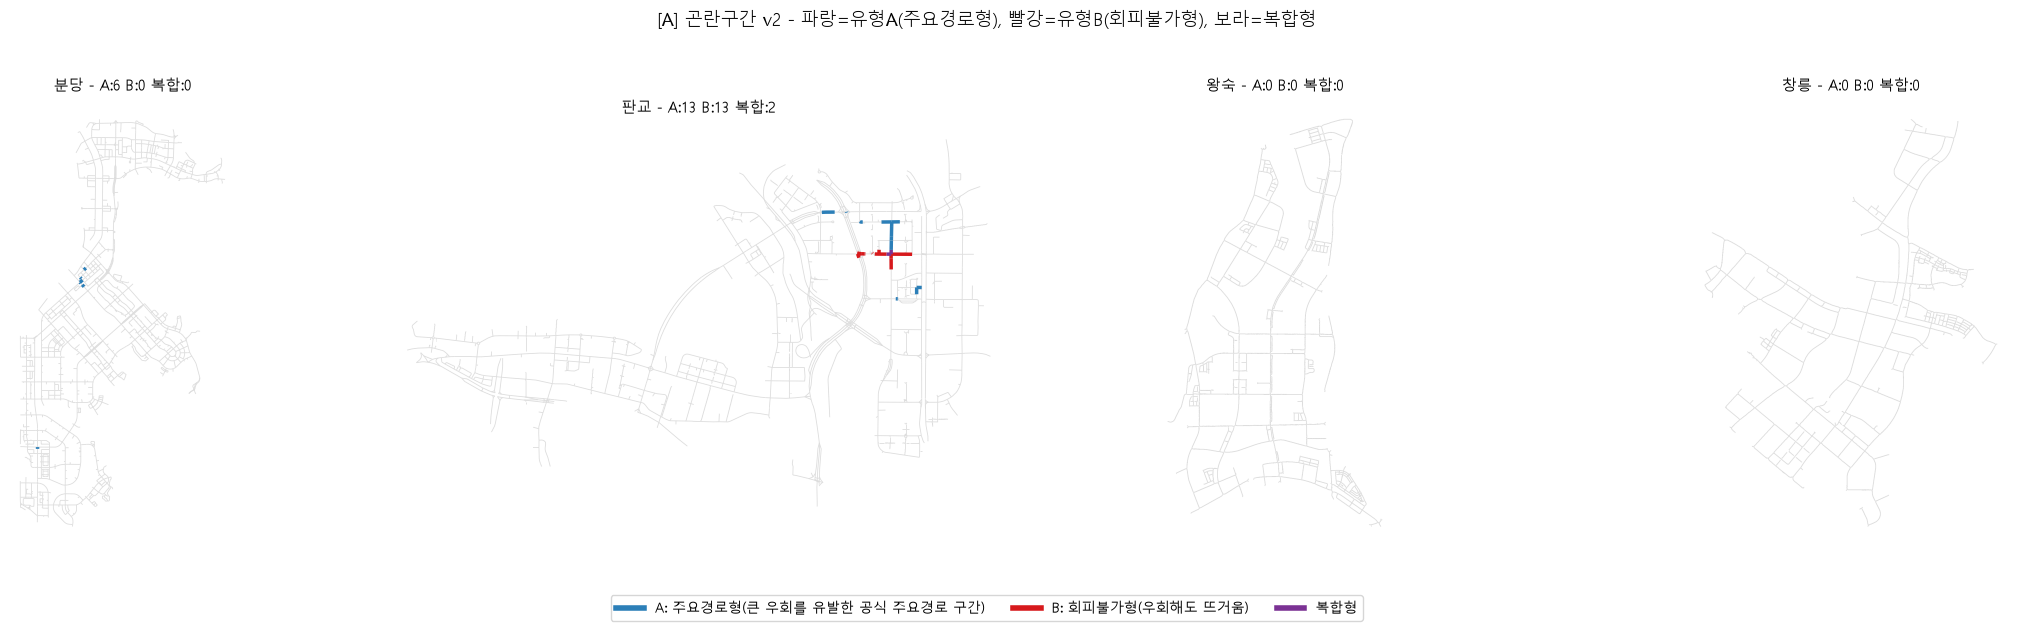

In [60]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
ZONES_ORDER = ["분당", "판교", "왕숙", "창릉"]
COLOR = {"A(주요경로형)": "#2C7FB8", "B(회피불가형)": "#D7191C", "복합형(A+B)": "#7B3294"}

fig, axes = plt.subplots(1, len(ZONES_ORDER), figsize=(24, 6))
for ax, zone in zip(axes, ZONES_ORDER):
    sub = final[final["zone"] == zone]
    sub.plot(ax=ax, color="#DDDDDD", linewidth=0.6)
    for label, color in COLOR.items():
        part = sub[sub["유형"] == label]
        if len(part) > 0:
            part.plot(ax=ax, color=color, linewidth=2.5)
    n_a = int((sub["유형"]=="A(주요경로형)").sum())
    n_b = int((sub["유형"]=="B(회피불가형)").sum())
    n_ab = int((sub["유형"]=="복합형(A+B)").sum())
    ax.set_title(f"{zone} - A:{n_a} B:{n_b} 복합:{n_ab}", fontsize=11)
    ax.set_axis_off()

fig.suptitle(f"[{NET_LABEL}] 곤란구간 v2 - 파랑=유형A(주요경로형), 빨강=유형B(회피불가형), 보라=복합형", fontsize=13)
handles = [plt.Line2D([0],[0], color=COLOR["A(주요경로형)"], lw=4, label="A: 주요경로형(큰 우회를 유발한 공식 주요경로 구간)"),
           plt.Line2D([0],[0], color=COLOR["B(회피불가형)"], lw=4, label="B: 회피불가형(우회해도 뜨거움)"),
           plt.Line2D([0],[0], color=COLOR["복합형(A+B)"], lw=4, label="복합형")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

## 요약

- 유형 A(주요경로형): 지구별 elbow로 "크게 돌아간 O-D"를 골라, 그 O-D들이 최단경로에서 피해간 링크(n_bypassed)를 heat_norm과 같은 방식(LISA+FDR)으로 공간군집 검정하고, heat_norm_HH_sig와의 겹침을 순열검정+초기하분포 정확검정으로 확인. is_main=True 조건에 더해, 지구 단위 Bonferroni 보정 p<0.05를 통과한 지구만 확정.
- 유형 B(회피불가형): exact(정확일치) 옆에 지구별 반경 민감도로 고른 buffered 버전을 병기. exact와 buffered 각각의 지구단위 Bonferroni 보정 p값 중 하나라도 유의해야 그 지구의 곤란구간_B가 살아남음. 둘 다 비유의하면 그 지구는 유형B 전체 0.
- 두 유형 모두 통계적 유의성(지구단위 Bonferroni 게이트 포함)과 심각도 상위 CAP_PER_TYPE_ZONE개 이내로만 확정 처리해 과다 산출 방지.
- 좌표계는 기존 최종_곤란구간.ipynb와 동일하게 EPSG:5179로 저장(재변환 없음).
- 저장 파일 A_곤란구간_확정_v2.geojson에 곤란구간_A / 곤란구간_A_확정 / 곤란구간_B_exact / 곤란구간_B_buffered / 곤란구간_B_확정 / 곤란구간_최종 / 유형 / 심각도_A / 심각도_B / n_bypassed 컬럼이 모두 들어있음.